<div style="background:#0047AB; color:#FFF; padding:15px; border-radius:5px;">
Introduction to Statistics
</div>

1. Range
2. Interquartile Range
3. Box Plots
4. Histograms
5. Mean
6. Median
7. Mode
8. Percentiles and Quartiles
9. Variance
10. Standard Deviation
11. Plots for univariate and bivariate analysis

<div style="background:#0047AB; color:#FFF; padding:15px; border-radius:5px;">
The backdrop
</div>

**Alex**, 19, works evenings and weekends as a **waiter** in a busy restaurant. Waiters earn a large part of their money from **tips**, the extra money customers leave on top of the bill.

For a few months, Alex wrote down **every table served**: the bill, the tip, whether the customers smoked, the day, lunch or dinner, and how many people were at the table. That notebook is a real, famous dataset called **`tips`**. It comes with the Python library **seaborn**, and data scientists all over the world use it to learn.

One evening, Alex sits down with the notebook and **The Question**:

> **The Question:**

1. What is the smallest and the biggest tip I get?
2. Which tips are unusual?
3. How much does a table usually tip?
4. Is a $5 tip a good tip?
5. Are some customers more predictable than others?
6. What makes a tip bigger?

Alex picks up different statistical tools to answer each part of **The Question**.

<div style="background:#0047AB; color:#FFF; padding:15px; border-radius:5px;">
Tiny maths cheat-sheet
</div>

| Symbol | Read it as | Example |
|---|---|---|
| $n$ | "how many numbers we have" | 7 tables → $n = 7$ |
| $x_1, x_2, \dots$ | "the 1st number, the 2nd number, …" | $x_1 = \$2$ |
| $\sum$ | "add them all up" (the Greek letter *sigma*) | $\sum x = 2 + 3 + 2.5 + \dots$ |
| $\bar{x}$ | "x-bar": the mean (average) | |
| $Q1, Q3$ | the first and third quartiles | |
| $\sigma$ or $s$ | the standard deviation (spread) | |


<div style="background:#0047AB; color:#FFF; padding:15px; border-radius:5px;">
Importing the libraries
</div>

In [3]:
# Load the tools we need

import numpy as np                # maths 
import pandas as pd               # tables 
import matplotlib.pyplot as plt   # drawing charts
import seaborn as sns             # prettier charts (and the tips dataset!)
from scipy import stats           # ready-made statistics formulas

In [5]:
# Defining the variables

sns.set_theme(style="whitegrid", context="talk", font_scale=0.8)
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["text.parse_math"] = False   # so "$" signs in titles print normally
BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#2E6FBA", "#E08A2B", "#3C9A5F", "#C8453B", "#8C8C8C", "#7B4FA0"
TIME_COLORS = {"Lunch": ORANGE, "Dinner": BLUE}
SMOKER_COLORS = {"No": BLUE, "Yes": RED}
DAYS = ["Thur", "Fri", "Sat", "Sun"]

<div style="background:#0047AB; color:#FFF; padding:15px; border-radius:5px;">
Importing the Dataset
</div>

The `tips` dataset is built into seaborn. `sns.load_dataset` downloads it the first time, so you need an internet connection.

In [7]:
# Load the dataset

df = sns.load_dataset("tips")
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns ")

The dataset has 244 rows and 7 columns 


In [9]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<div style="background:#0047AB; color:#FFF; padding:15px; border-radius:5px;">
Understanding the Columns
</div>

| Column | Meaning |
|---|---|
| `total_bill` | the bill for the table, in US dollars ($) |
| `tip` | the tip the table left ($) |
| `sex` | sex of the person who paid (Male / Female) |
| `smoker` | was there a smoker at the table? (Yes / No) |
| `day` | day of the week (Thur, Fri, Sat, Sun) |
| `time` | Lunch or Dinner |
| `size` | how many people were at the table |

Each row is **one table** that Alex served. There are **244 tables**.

We add **one extra column**: the tip as a **percentage of the bill**. A $3 tip on a $10 bill (30 %) is much more generous than a $3 tip on a $60 bill (5 %).

In [ ]:
# Add a new column: tip as a percentage of the bill



In [ ]:
# How big is the dataset?



<div style="background:#0047AB; color:#FFF; padding:15px; border-radius:5px;">
Alex's weekend: 7 tables
</div>

To do maths by hand we need small numbers. Here are the tips from **7 real tables** in the dataset that Alex served one weekend:

$$\$2,\quad \$3,\quad \$2.50,\quad \$3,\quad \$4,\quad \$10,\quad \$3.50$$

Six were ordinary tips. The **\$10** came from a party of three with the **biggest bill in the whole dataset** (\$50.81). Keep an eye on this big number: it will teach us a lot.

In [11]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [13]:
# The 7 tables (row numbers in the dataset)

alex_tables = df.loc[[26,29,31,32,109,170,91],['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']]

In [17]:
alex_tables['tip'].values

array([ 2. ,  3. ,  2.5,  3. ,  4. , 10. ,  3.5])

In [19]:
# Keep just the tips, as a simple list of numbers

alex = alex_tables['tip'].values

In [21]:
alex

array([ 2. ,  3. ,  2.5,  3. ,  4. , 10. ,  3.5])

<div style="background:#0047AB; color:#FFF; padding:15px; border-radius:5px;">
Part A: How spread out are the tips?
</div>

*The Question, part 1: "What's the smallest and biggest tip I get, and which tips are unusual?"*


<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="color:#004d99;"><h3> What is the smallest and the biggest tip Alex gets? </h3></div>

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3>RANGE</h3>
</div>

$$\text{Range} = \text{largest value} - \text{smallest value}$$

The **range** tells you how wide the data stretches, from the lowest value to the highest. It's quick to calculate, but it only looks at **two** numbers, so a single extreme value can make it huge.

**Weather picture:** if today's lowest temperature was 12 °C and the highest was 27 °C, the range is 15 °C.

<div style="color:#004d99;"><h3> Where is the range used ? </h3></div>

1. **Checking data for mistakes:** a tip of −\$5  and  \$5,000 means someone typed something wrong.
2. **Rescaling data for AI:** "min-max scaling" squeezes every number into 0–1 using $\dfrac{x - \min}{\max - \min}$.
3. **Quality control in factories:** the range of 5 measurements is checked every hour.
4. **Stock charts and weather reports:** each day's "high – low" range shows how jumpy things were.

<div style="color:#004d99;"><h3> Calculate the range with a pen and a paper </h3></div>

Alex's tips in $ : 2, 3, 2.50, 3, 4, 10, 3.50

**Step 1: find the smallest and the biggest:** smallest = \$2, biggest = \$10

**Step 2: subtract:**
$$\text{Range} = 10 - 2 = \mathbf{\$8}$$

**Notice:** without the 10 table, the range would be 4 - 2 = 2. One unusual table made the range "4 times bigger"



<div style="color:#004d99;"><h3> An example of why I would like to understand the range of a given distribution </h3></div>

A new waiter joins and asks Alex: *"What's the worst and the best tip I can expect from one table, at lunch and at dinner?"* The **range** (smallest to biggest tip) gives a quick first answer.

<div style="color:#004d99;"><h3> Calculate Range in Python </h3></div>

**Problem:**

1. What are the smallest tip, the biggest tip and the range of all tips?
2. What is the range of tips at lunch and at dinner?
3. What is the range of tips on each day?
4. Squeeze the total bill into a 0–1 scale (min-max scaling).

In [27]:
# 1. Smallest tip, biggest tip and the range

max_tip = df['tip'].max()
min_tip = df['tip'].min()

print(f"the largest values {max_tip} and smallest value is {min_tip}")

the largest values 10.0 and smallest value is 1.0


In [33]:
# range?

data_range = max_tip - min_tip

print(f"the range of the data ${data_range}")

the range of the data $9.0


In [ ]:
#

In [55]:
df[['tip']]

,tip
0,1.01
1,1.66
2,3.50
3,3.31
4,3.61
...,...
239,5.92
240,2.00
241,2.00
242,1.75


In [53]:
# 2. Range of tips at lunch and at dinne

lunch_range = df[df['time'] == 'Lunch']['tip'].max() - df[df['time']== 'Lunch']['tip'].min()
dinner_range = df[df['time']=='Dinner']['tip'].max() - df[df['time']=='Dinner']['tip'].min()

print(f"range of lunch {lunch_range} and range of dinner {dinner_range}")

range of lunch 5.45 and range of dinner 9.0


In [61]:
# 3. Range of tips on each day


result = df.groupby('day')['tip'].agg(['max','min'])

result['range'] = result['max'] - result['min']

print(result)

        max   min  range
day                     
Thur   6.70  1.25   5.45
Fri    4.73  1.00   3.73
Sat   10.00  1.00   9.00
Sun    6.50  1.01   5.49


/var/folders/d9/zn0fzv5j3wv4ldx8c1wgtq9h0000gn/T/ipykernel_4075/2711279870.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  result = df.groupby('day')['tip'].agg(['max','min'])


NameError: name 'by_day' is not defined

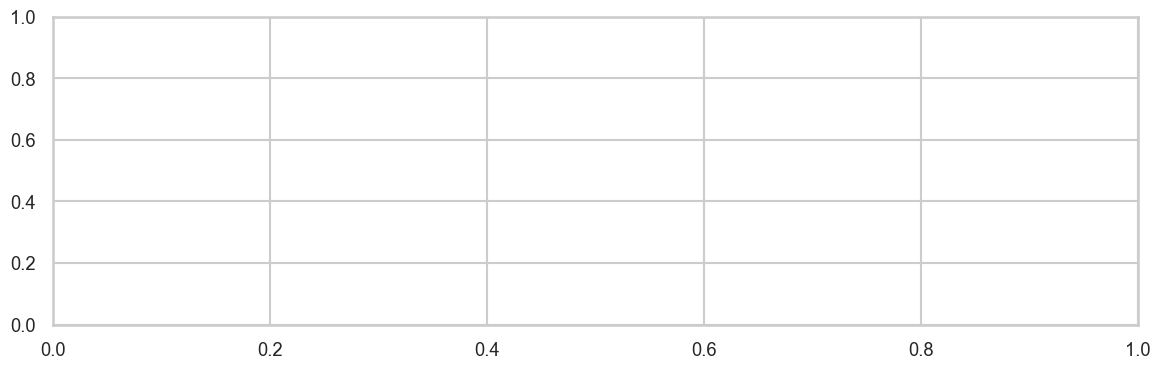

In [63]:
# (For Tuesday) Range of tip by day

# specify the canvas and the plot size
fig, ax = plt.subplots(1, 1, figsize=(14, 4))

for i, d in enumerate(DAYS):
    row = by_day.loc[d]
    plt.plot([row["smallest"], row["biggest"]], [i, i], color=BLUE, lw=12, solid_capstyle="round")   
    plt.text(row["biggest"] + 0.2, i, f"range = ${row['range']:.2f}", va="center")
plt.yticks(range(len(DAYS)), DAYS)
plt.xlim(0, 12.5)
plt.title("Range of tips on each day: from the smallest tip to the biggest")
plt.xlabel("Tip ($)")
plt.tight_layout()
plt.show()

<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="color:#004d99;"><h3> Which tips are unusual? </h3></div>

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3>Interquartile Range (IQR)</h3>
</div>

First, **quartiles**: sort the data and cut it into **4 equal groups**, like cutting a sandwich into quarters.
- **Q1** (first quartile): a quarter of the values are below it
- **Q2** (the median): half are below it
- **Q3** (third quartile): three quarters are below it



$$\text{IQR} = Q3 - Q1$$

The **IQR** is the width of the **middle 50 %** of the data. It throws away the lowest 25 % and the highest 25 %, so **extreme values can't fool it**.

**Outlier detector:** a value is flagged as an **outlier** (unusual, worth checking) if it is
- **below** $Q1 - 1.5 \times \text{IQR}$, or
- **above** $Q3 + 1.5 \times \text{IQR}$.

These two cut-offs are called **fences** (invented by the statistician John Tukey).

<div style="color:#004d99;"><h3> Where is the IQR used ? </h3></div>

1. **Cleaning data:** the most popular way to find weird or wrong values before training an AI.
2. **Box plots** are drawn using the IQR.
3. **Fraud detection:** a payment far outside a customer's usual range gets flagged.
4. **Fair comparisons** of spread when data has extreme values (incomes, house prices).

<div style="color:#004d99;"><h3> Calculate the IQR with a pen and a paper </h3></div>

Alex's tips **sorted** in $ : 2, 2.50, 3, 3, 3.50, 4, 10  

Number of elements (n) = 7; with positions 0 through 6

We use the rule Python uses: **position** $= (n - 1) \times \dfrac{p}{100}$

| Quartile | Position | Value |
|---|---|---|
| Q1 (p = 25) | $6 \times 0.25 = 1.5$ | halfway between \$2.50 and \$3 → **\$2.75** |
| Q3 (p = 75) | $6 \times 0.75 = 4.5$ | halfway between \$3.50 and \$4 → **\$3.75** |

$$\text{IQR} = 3.75 - 2.75 = \mathbf{\$1}$$

**Fences:**
- Lower fence $= 2.75 - 1.5 \times 1 = \$1.25$
- Upper fence $= 3.75 + 1.5 \times 1 = \$5.25$

**Check each tip:** 2, 2.50, 3, 3, 3.50, 4 are inside $[\$1.25,\ \$5.25]$. **10 is above 5.25 and hence it is treated as an  outlier!**

Compare: 

- Range = 8 
- IQR = 1 

<div style="color:#004d99;"><h3> Calculate Interquartile Range in Python </h3></div>

In [65]:
# use the pandas describe function

alex_tables['tip'].describe()

count     7.000000
mean      4.000000
std       2.723356
min       2.000000
25%       2.750000
50%       3.000000
75%       3.750000
max      10.000000
Name: tip, dtype: float64

<div style="color:#004d99;"><h3> How do we represent box plots of a distribution using a plot </h3></div>

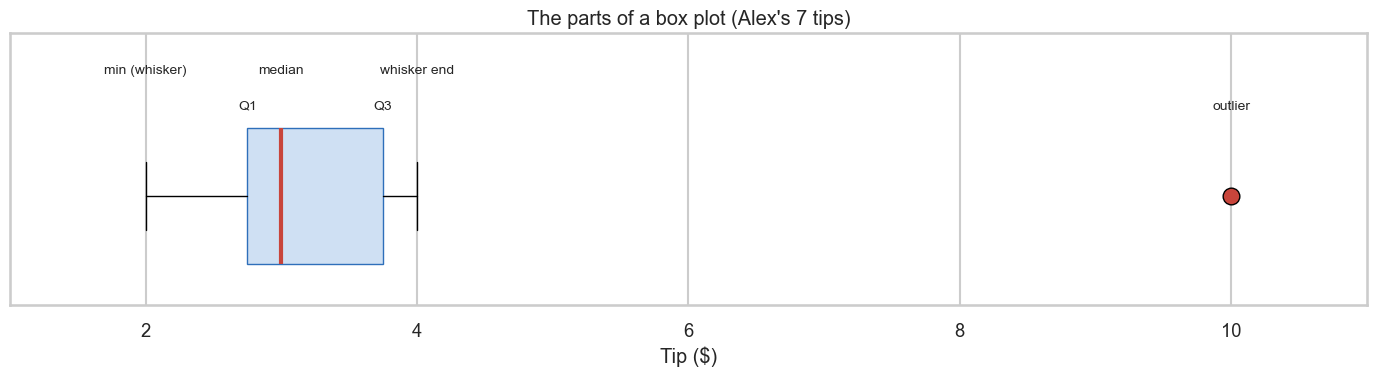

In [67]:
# for Alex's 7 tables only: a labelled box plot

# specify the canvas and the plot size
fig, ax = plt.subplots(1, 1, figsize=(14, 4))

plt.boxplot(alex, vert=False, widths=0.5, patch_artist=True,
            boxprops=dict(facecolor="#CFE0F3", color=BLUE), medianprops=dict(color=RED, lw=3),
            flierprops=dict(marker="o", markerfacecolor=RED, markersize=12))


for v, name, y in [(2, "min (whisker)", 1.45), (2.75, "Q1", 1.32), (3, "median", 1.45), (3.75, "Q3", 1.32), (4, "whisker end", 1.45), (10, "outlier", 1.32)]:
    plt.text(v, y, name, ha="center", fontsize=10)        # label each part of the box plot (staggered so they don't overlap)

plt.title("The parts of a box plot (Alex's 7 tips)")
plt.xlabel("Tip ($)")
plt.yticks([])
plt.xlim(1, 11)
plt.ylim(0.6, 1.6)
plt.tight_layout()
plt.show()

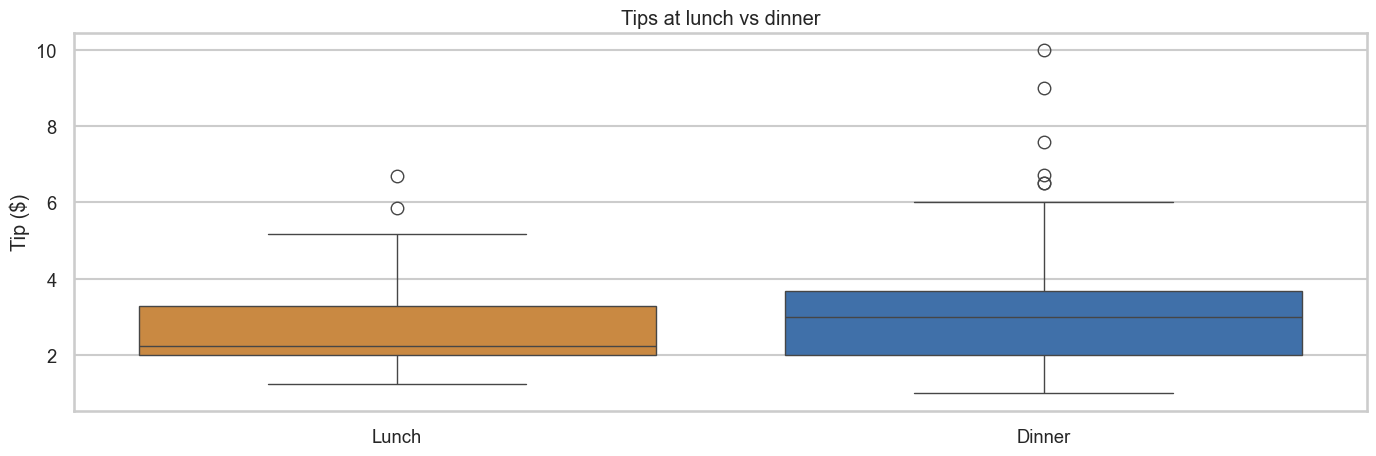

In [69]:
# tips at lunch vs dinner

# specify the canvas and the plot size
fig, ax = plt.subplots(1, 1, figsize=(14, 4.8))

sns.boxplot(data=df, x="time", y="tip", hue="time", palette=TIME_COLORS, legend=False)
plt.title("Tips at lunch vs dinner")
plt.xlabel("")
plt.ylabel("Tip ($)")
plt.tight_layout()
plt.show()

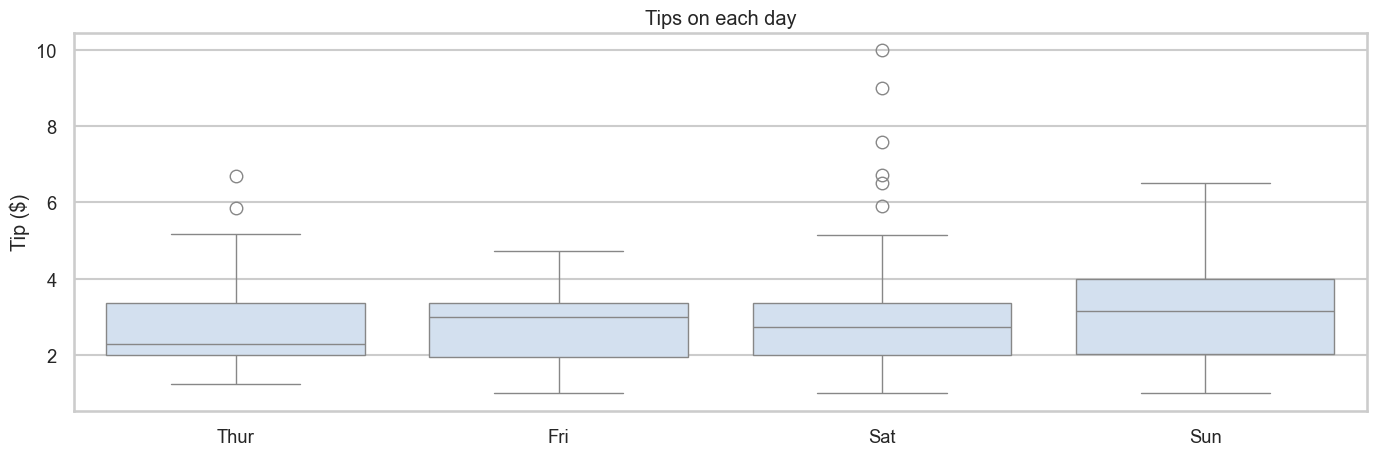

In [71]:
# tips on each day

# specify the canvas and the plot size
fig, ax = plt.subplots(1, 1, figsize=(14, 4.8))

sns.boxplot(data=df, x="day", y="tip", order=DAYS, color="#CFE0F3")
plt.title("Tips on each day")
plt.xlabel("")
plt.ylabel("Tip ($)")
plt.tight_layout()
plt.show()

<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3>Histograms</h3>
</div>


A **histogram** is a picture of how data is spread out:
1. Chop the number line into equal **bins** (e.g. \$1–\$2, \$2–\$3, …).
2. **Count** how many values fall into each bin.
3. Draw a **bar** for each count.

It shows the **shape** of the data: is it symmetric or lopsided? One hump or two? Any gaps? Any values far away from the rest?

**Bin size matters:** bins that are too wide hide the details; bins that are too narrow look like noise. 

**How to select the number of bins:** A simple starting rule (*Sturges' rule*): number of bins $\approx 1 + \log_2(n)$.

**(Piggy Bank Example) Sweet-jar picture:** tip all the tips into jars labelled

- 1–2
- 2–3
- 3-4

… and then line up the jars. 

The height of each jar's pile is the histogram.

<div style="color:#004d99;"><h3> Where is histograms used ? </h3></div>

1. **First look at any dataset** (*exploratory data analysis*, EDA): data scientists draw histograms before doing anything else.
2. **Spotting mistakes:** a bar at "age = 200" jumps out immediately.
3. **Choosing a model:** a lopsided histogram tells you to transform the data (e.g. use a log) or use a different model.
4. **Checking AI models:** a histogram of the model's errors should be centred on zero.
5. **Photos:** your phone's camera app uses a histogram of pixel brightness to fix exposure.

<div style="color:#004d99;"><h3> Calculate the number of bins using Sturges rule </h3></div>

In [75]:
# 1. Sturges' rule for the number of bins (https://www.omnicalculator.com/math/log-2)


k = int(np.ceil(1+np.log2(len(df))))

<div style="color:#004d99;"><h3> Prepare a Standard Histogram </h3></div>

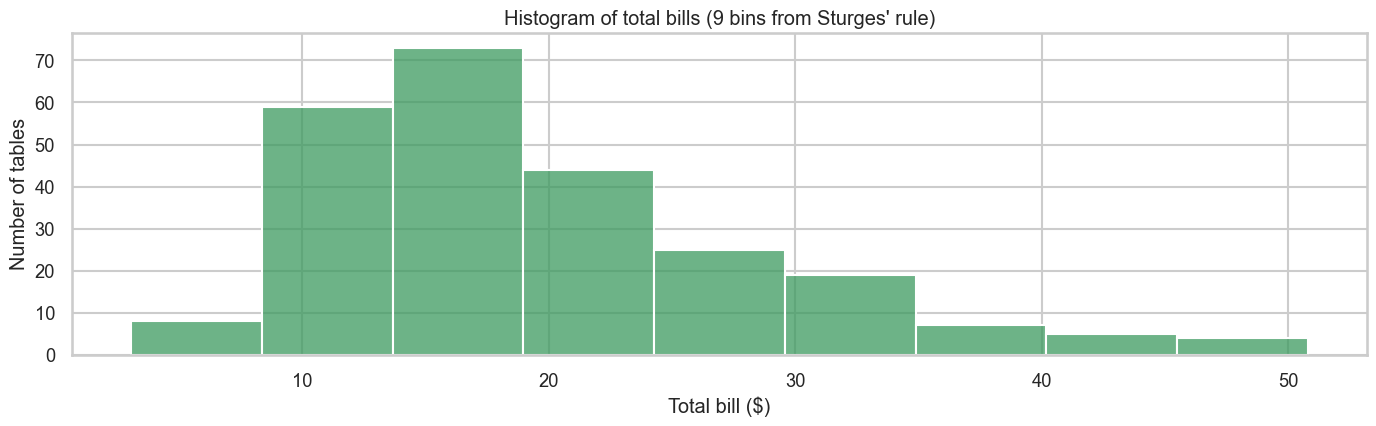

In [79]:
# all 244 total bills: histogram with Sturges' number of bins

# specify the canvas and the plot size
fig,ax = plt.subplots(1,1,figsize=(14,4.5))

sns.histplot(df["total_bill"], bins=k, color=GREEN)
plt.title(f"Histogram of total bills ({k} bins from Sturges' rule)")
plt.xlabel("Total bill ($)")
plt.ylabel("Number of tables")
plt.tight_layout()
plt.show()

<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="background:#0047AB; color:#FFF; padding:15px; border-radius:5px;">
Part B: What is a typical tip, and how much does it wobble?
</div>

*The Question, part 2: "How much does a table usually tip? Is a $5 tip a good tip? Are some customers more predictable than others? And what makes a tip bigger?"*

In Part A we looked at the **spread** of the tips. Now we find the **centre** ("what's typical?"), learn how to **rank** a tip against all the others, describe the **shape** with smooth curves, measure the **wobble** exactly, and finally look at **how two things relate**.

<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="color:#004d99;"><h3> How much does a table usually tip? </h3></div>

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3>Mean</h3>
</div>

The **mean** (or **average**) is what you get when you **add up all the numbers and divide by how many there are**.

$$\text{Mean} = \frac{\text{sum of all values}}{\text{number of values}} \qquad\text{or in symbols}\qquad \bar{x} = \frac{\sum x}{n}$$

**Pizza picture:** 3 friends ate 2, 3 and 7 slices. If they had shared *fairly*, each would get $(2+3+7)/3 = 4$ slices. The mean is the "fair share".

**See-saw picture:** put every number on a see-saw; the mean is the point where it balances. A single heavy number far away can tip the balance point a lot.

<div style="color:#004d99;"><h3> Where is the mean used ? </h3></div>

1. **Everyday dashboards:** average order value, average screen time, average delivery time.
2. **Filling gaps:** if one value is missing, data scientists often fill it with the average.
3. **Checking AI models:** on average, how wrong were the predictions? (*mean error*)
4. **Training AI:** a neural network learns by making its **average mistake** smaller and smaller.
5. **A/B testing:** does a new menu increase the **average** bill?

<div style="color:#004d99;"><h3> Calculate the mean with a pen and a paper </h3></div>

Alex's tips: 2, 3, 2.50, 3, 4, 10, 3.50

**Step 1: add them up**
2 + 3 + 2.5 + 3 + 4 + 10 + 3.5 = 28

**Step 2: count them**
n = 7

**Step 3: divide**
$\text{Mean} = \dfrac{28}{7} = \mathbf{\$4}$

**Notice:** six of the seven tables tipped 4 or less, yet the average says 4! The single 10 tip pulled the average up. Without it, the mean would be 18 / 6 = 3.

<div style="color:#004d99;"><h3> An example of why I would like to understand the mean of a given distribution </h3></div>

Alex expects to serve **30 tables** next Saturday and wants to know roughly how much money to expect in tips. A good estimate is:

$$\text{expected tips} = \text{mean tip per table} \times \text{number of tables}$$

The mean is the right tool here because Alex cares about the **total**, and the total includes the generous tables too.

<div style="color:#004d99;"><h3> Calculate Mean in Python </h3></div>

**Problem:**

1. What is the mean tip of all 244 tables?
2. What is the mean tip on each day? At lunch vs dinner?
3. Estimate Alex's tips for a Saturday with 30 tables.

In [81]:
# 1. Mean of all tips

df['tip'].mean()

2.99827868852459

In [101]:
# The same thing manually: add up and divide by how many

df['tip'].sum() / len(df)

2.99827868852459

In [103]:
# 2. Mean tip for each day (groupby = split the table into groups)

df.groupby('day',observed=True)['tip'].mean()

day
Thur    2.771452
Fri     2.734737
Sat     2.993103
Sun     3.255132
Name: tip, dtype: float64

In [109]:
# 2.1 Mean tip at lunch and at dinner

df.groupby(['day','time',],observed=True)['tip'].mean()

day   time  
Thur  Lunch     2.767705
      Dinner    3.000000
Fri   Lunch     2.382857
      Dinner    2.940000
Sat   Dinner    2.993103
Sun   Dinner    3.255132
Name: tip, dtype: float64

In [111]:
# 3. Planning for Saturday

df[df['day'] == 'Sat'].groupby('day',observed=True)['tip'].mean()

day
Sat    2.993103
Name: tip, dtype: float64

<div style="color:#004d99;"><h3> How do we represent the mean of a distribution using a plot </h3></div>

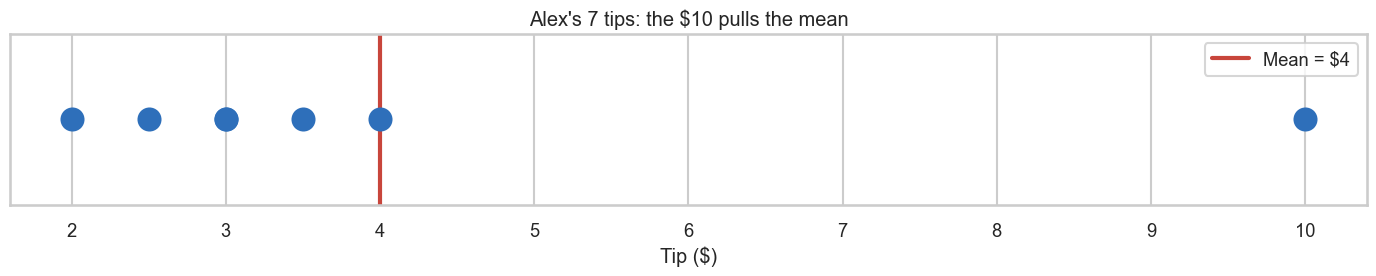

In [113]:
# for Alex's 7 tables only

# specify the canvas and the plot size
fig,ax = plt.subplots(1,1,figsize=(14,3))

# Alex's tips as dots with the mean line
plt.scatter(alex, np.zeros_like(alex), s=250, color=BLUE, zorder=3)        # all coordinates become (x, 0)
plt.axvline(alex.mean(), color=RED, lw=3, label=f"Mean = ${alex.mean():.0f}")   # draw an 'axes vertical line' at the mean
plt.title("Alex's 7 tips: the $10 pulls the mean")
plt.xlabel("Tip ($)")
plt.yticks([])
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# mean tip by day



<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3>Median</h3>
</div>

The **median** is the **middle number** after you sort the numbers from smallest to largest. Half the values are below it and half are above it.

- **Odd** number of values → the median is the one exactly in the middle.
- **Even** number of values → take the two middle ones and find their average.

**Line-up picture:** line up 7 students by height. The 4th student is the median height. Even if the tallest student is replaced by a 3-metre giant, the **middle student stays the same**. That's why the median isn't fooled by extreme values.

<div style="color:#004d99;"><h3> Where is the median used ? </h3></div>

1. **House prices and salaries** are usually reported as medians, because a few billionaires would make the mean misleading.
2. **App speed:** tech companies track the *median* loading time.
3. **Filling gaps** in lopsided data (e.g. incomes) uses the median instead of the mean.
4. **Spotting lopsided data:** if the mean and median are far apart, a few extreme values are pulling the mean.

<div style="color:#004d99;"><h3> Calculate the median with a pen and a paper </h3></div>

Alex's tips: \$2, \$3, \$2.50, \$3, \$4, \$10, \$3.50

**Step 1: sort them**
$2,\ 2.5,\ 3,\ \boxed{3},\ 3.5,\ 4,\ 10$

**Step 2: find the middle.** There are 7 numbers, so the middle is the $(7+1)/2 = $ **4th** number → **Median = \$3**.



<div style="color:#004d99;"><h3> An example of why I would like to understand the median of a given distribution </h3></div>

A new waiter asks Alex: *"What's a **normal** tip here?"* The mean tip (\$3.00) is nudged up by a few very generous tables, so Alex gives the **median** (\$2.90) as the honest answer. 

<div style="color:#004d99;"><h3> Calculate Median in Python </h3></div>

**Problem:**

1. Find the mean and median tip. Which is bigger, and why?
2. Find the mean and median total bill.
3. Find the mean and median tip percentage.
4. Find the mean and median tip on each day.

In [117]:
# 1. Mean vs median tip

print(df['tip'].mean())
print(df['tip'].median())

2.99827868852459
2.9


In [119]:
# 2. Mean vs median total bill

print(df['total_bill'].mean())
print(df['total_bill'].median())

19.78594262295082
17.795


In [ ]:
# 3. Mean vs median tip percentage



In [123]:
# 4. Mean vs median tip on each day

df.groupby('day',observed=True)['tip'].agg(['mean','median'])

,mean,median
day,,
Thur,2.771452,2.305
Fri,2.734737,3.000
Sat,2.993103,2.750
Sun,3.255132,3.150


<div style="color:#004d99;"><h3> How do we represent the median of a distribution using a plot </h3></div>

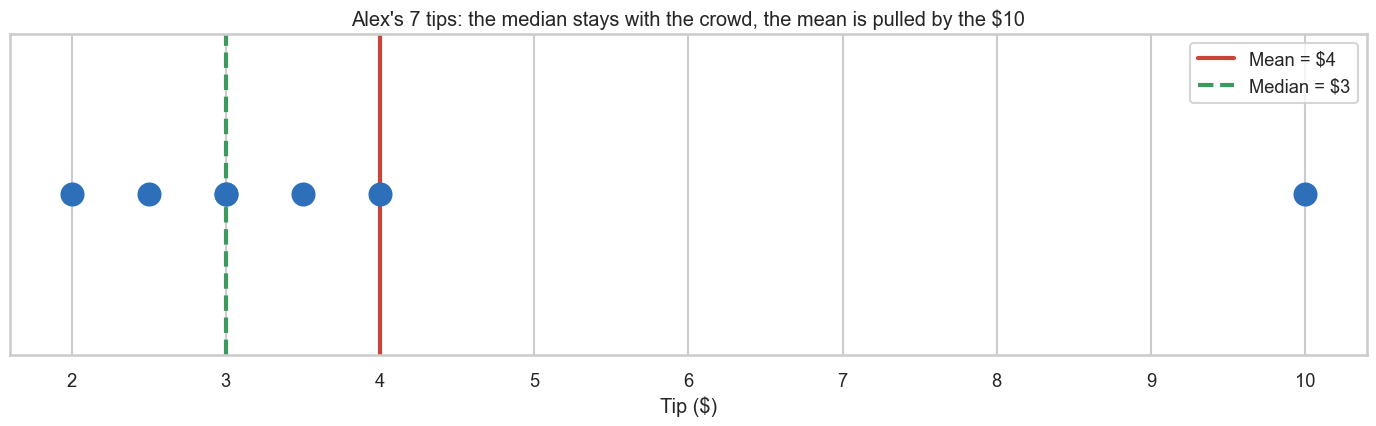

In [125]:
# for Alex's 7 tables only: mean vs median

# specify the canvas and the plot size
# for Alex's 7 tables only: mean vs median

# specify the canvas and the plot size
fig, ax = plt.subplots(1, 1, figsize=(14, 4.5))

plt.scatter(alex, np.zeros_like(alex), s=250, color=BLUE, zorder=3)
plt.axvline(alex.mean(), color=RED, lw=3, label=f"Mean = ${alex.mean():.0f}")                    # the balance point
plt.axvline(np.median(alex), color=GREEN, lw=3, ls="--", label=f"Median = ${np.median(alex):.0f}")   # the middle value
plt.title("Alex's 7 tips: the median stays with the crowd, the mean is pulled by the $10")
plt.xlabel("Tip ($)")
plt.yticks([])
plt.legend()
plt.tight_layout()
plt.show()

<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="color:#004d99;"><h3> What is the most common tip, and the most common table? </h3></div>

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3>Mode</h3>
</div>

The **mode** is the value that appears **most often**.

- It is the only "typical value" that works for **words or categories**. You can't average "Saturday" and "Sunday", but you *can* ask which day is busiest.
- Data can have **one mode**, **two modes** (*bimodal*) or **no mode** (when nothing repeats).

**Shoe-shop picture:** a shoe shop doesn't care about the *average* shoe size (it might be 7.38, which doesn't exist!). It wants the **most common** size so it can stock more of it. That's the mode.

<div style="color:#004d99;"><h3> Where is the mode used ? </h3></div>

1. **Filling gaps in categories:** if a survey answer is missing, fill it with the most common answer.
2. **The simplest AI model:** always guess the most common answer. Any smarter AI must beat this "baseline".
3. **Voting in AI:** a *random forest* asks hundreds of small decision trees and takes the **most common** vote.
4. **Business:** best-selling dish, busiest day, most common table size.

<div style="color:#004d99;"><h3> Calculate the mode with a pen and a paper </h3></div>

Alex's tips sorted: \$2, \$2.50, \$3, \$3, \$3.50, \$4, \$10

Make a **tally table**:

| Tip | \$2 | \$2.50 | \$3 | \$3.50 | \$4 | \$10 |
|---|---|---|---|---|---|---|
| Tally | I | I | **II** | I | I | I |
| Count | 1 | 1 | **2** | 1 | 1 | 1 |

→ **Mode = \$3** (it appears twice).

So for Alex: Mean = \$4, Median = \$3, Mode = \$3. Three different ways to say "typical"!

<div style="color:#004d99;"><h3> An example of why I would like to understand the mode of a given distribution </h3></div>

The owner is rearranging the dining room. Most parties are **2 people** (the mode of `size`), so it makes sense to have **more tables for two**. The owner also puts the most waiters on the **busiest day** (the mode of `day`).

<div style="color:#004d99;"><h3> Calculate Mode in Python </h3></div>

**Problem:**

1. What is the most common tip?
2. What is the most common table size?
3. What is the busiest day?
4. Is lunch or dinner more common?
5. The "lazy guesser": if we always guess the most common answer to "is there a smoker at the table?", how often are we right?

In [127]:
# 1. Most common tip

df['tip'].mode()

0    2.0
Name: tip, dtype: float64

<div style="color:#004d99;"><h3> How do we represent the mode of a distribution using a plot </h3></div>

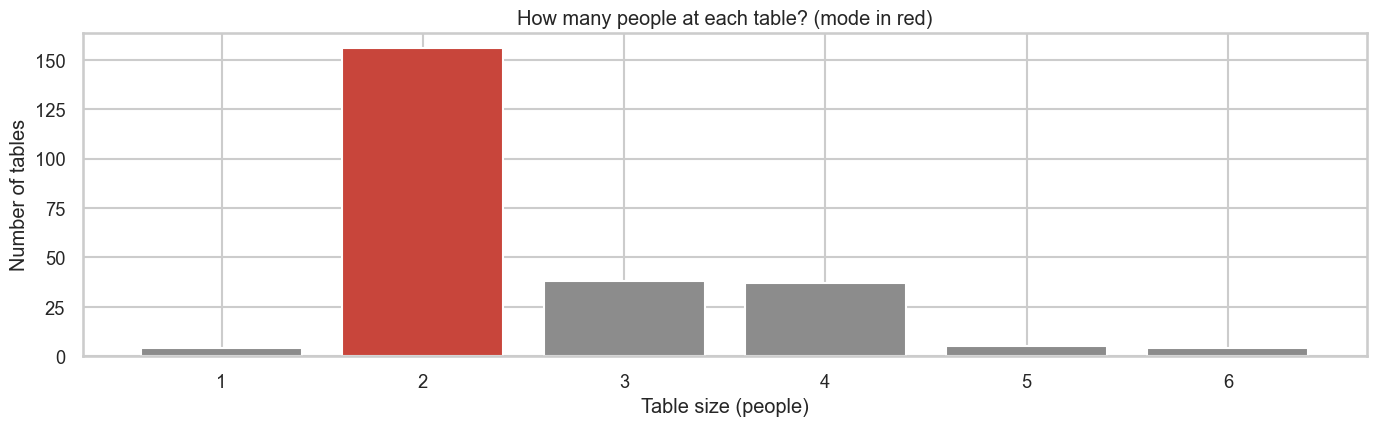

In [129]:
# table sizes (mode in red)

# specify the canvas and the plot size
# table sizes (mode in red)

# specify the canvas and the plot size
fig, ax = plt.subplots(1, 1, figsize=(14, 4.5))

counts = df["size"].value_counts().sort_index()
colors = [RED if s == counts.idxmax() else GREY for s in counts.index]     # highlight the tallest bar
plt.bar(counts.index, counts.values, color=colors)
plt.title("How many people at each table? (mode in red)")
plt.xlabel("Table size (people)")
plt.ylabel("Number of tables")
plt.tight_layout()
plt.show()

<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3>Percentiles and Quartile</h3>
</div>

A **percentile** tells you what **percentage of values are below** a certain number.

- If your test score is at the **90th percentile**, you did better than 90 % of students.
- Babies' heights and weights are tracked with percentiles at the doctor.

**Quartiles** are special percentiles that cut the sorted data into **4 equal groups**:

| Name | Percentile | Meaning |
|---|---|---|
| **Q1** | 25th | a quarter of the values are below it |
| **Q2** (median) | 50th | half are below it |
| **Q3** | 75th | three quarters are below it |

**Min, Q1, Median, Q3, Max** together are called the **five-number summary**.

<div style="color:#004d99;"><h3> Where is percentiles and quartiles used ? </h3></div>

1. **Exam results and rankings:** "top 10 %" of students or players.
2. **App speed:** "99 % of pages load within 1 second" (the 99th percentile).
3. **Grouping customers:** split them into 4 equal groups by spending (quartiles).
4. **Finding weird values:** quartiles are used to spot outliers (A2).
5. **Risk:** "a 1-in-100-year flood" is a percentile idea.

<div style="color:#004d99;"><h3> Calculate percentiles and quartiles with a pen and a paper </h3></div>

Alex's tips sorted: \$2, \$2.50, \$3, \$3, \$3.50, \$4, \$10 (positions 0 to 6)

**Quartiles** (rule: position $= (n - 1) \times p/100$):

| Quartile | Position | Value |
|---|---|---|
| Q1 (p = 25) | 1.5 | halfway between \$2.50 and \$3 → **\$2.75** |
| Median (p = 50) | 3 | **\$3** |
| Q3 (p = 75) | 4.5 | halfway between \$3.50 and \$4 → **\$3.75** |



<div style="color:#004d99;"><h3> An example of why I would like to understand percentiles and quartiles of a given distribution </h3></div>

A table leaves Alex **\$5**. Is that good? A percentile answers it: *"\$5 is more than X % of all tips."* The owner also wants to know if **bigger bills** lead to bigger tips, so Alex splits the tables into **4 equal groups by bill size** (quartiles) and compares their tips.

<div style="color:#004d99;"><h3> Calculate Percentiles and Quartiles in Python </h3></div>

**Problem:**

1. Find the five-number summary of all tips.
2. What tip puts a table in the top 10 % (90th percentile)?
3. What percentile is a $5 tip?
4. Split the tables into 4 equal groups by total bill (quartiles). What is the mean tip and tip % in each group?

In [131]:
# 1. Five-number summary of all tips

tip = df["tip"]

print(f"Min    = ${tip.min():.2f}")
print(f"Q1     = ${tip.quantile(0.25):.2f}")
print(f"Median = ${tip.median():.2f}")
print(f"Q3     = ${tip.quantile(0.75):.2f}")
print(f"Max    = ${tip.max():.2f}")

Min    = $1.00
Q1     = $2.00
Median = $2.90
Q3     = $3.56
Max    = $10.00


In [133]:
# 2. Top 10% of tips (90th percentile)
 
top10 = tip.quantile(0.90)

print(f"A tip of ${top10:.2f} or more puts a table in the top 10%")

A tip of $5.00 or more puts a table in the top 10%


<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3>Variance</h3>
</div>


**Variance** measures how much the values **wobble around the mean**.

How to build it:
1. Find the mean.
2. For each value, find its **distance from the mean** (its *deviation*).
3. **Square** each distance. This makes every distance positive, and it makes big distances count much more.
4. Average the squares. For a sample we divide by $n - 1$ instead of $n$; this small correction gives a fairer estimate.

$$s^2 = \frac{\sum (x - \bar{x})^2}{n - 1}$$

**Small variance** → values huddle close to the mean (predictable). **Big variance** → values are scattered (unpredictable).

**One annoyance:** the units get squared (dollars²!). That's why we usually take the square root → the **standard deviation** (discussed next).

<div style="color:#004d99;"><h3> Where is the variance used ? </h3></div>

1. **Finance and risk:** variance is the classic measure of risk.

<div style="color:#004d99;"><h3> Calculate the variance with a pen and a paper </h3></div>

Alex's tips, mean $\bar{x} = \$4$:

| Tip $x$ | Distance from mean $(x - 4)$ | Squared distance |
|---|---|---|
| 2 | −2 | 4 |
| 3 | −1 | 1 |
| 2.50 | −1.5 | 2.25 |
| 3 | −1 | 1 |
| 4 | 0 | 0 |
| 10 | +6 | 36 |
| 3.50 | −0.5 | 0.25 |
| | **Sum = 0** (always!) | **Sum = 44.5** |

$$s^2 = \frac{44.5}{7 - 1} = \frac{44.5}{6} = \mathbf{7.42}$$

The \$10 tip alone contributes 36 of the 44.5: squaring makes far-away values **very** loud.

**Without the \$10** (2, 3, 2.50, 3, 4, 3.50, mean \$3): squared distances 1, 0, 0.25, 0, 1, 0.25 → sum 2.5 → $s^2 = 2.5/5 = 0.5$.

<div style="color:#004d99;"><h3> Calculate Variance in Python </h3></div>

**Problem:**

1. Calculate the variance of Alex's 7 tips step by step, and check it with numpy.
2. Find the variance of the tip percentage for smokers and non-smokers.
3. How many times bigger is the smokers' variance?
4. Find the variance of tips at lunch and at dinner.

In [ ]:
# 1a. Step by step, just like on paper



<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="color:#004d99;"><h3> How much does a tip usually wobble around the average? </h3></div>

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3>Standard Deviation  </h3>
</div>

The **standard deviation** (SD, written $s$ or $\sigma$) is simply the **square root of the variance**:

$$s = \sqrt{\text{variance}}$$

Taking the square root brings the units back to dollars, so it's easy to understand: *"tips are typically about s dollars away from the average."*

**The 68 – 95 – 99.7 rule** (for bell-shaped data):
- about **68 %** of values are within **1 SD** of the mean,
- about **95 %** within **2 SD**,
- about **99.7 %** within **3 SD**.

A value more than 3 SD from the mean is **very** unusual. The **z-score** $z = \dfrac{x - \text{mean}}{\text{SD}}$ tells you how many SDs away a value is.

<div style="color:#004d99;"><h3> Where is the standard deviation used ? </h3></div>

1. **Finance:** a share's *volatility* is its standard deviation.

<div style="color:#004d99;"><h3> Calculate the standard deviation with a pen and a paper </h3></div>

From previous example: variance $= 7.42$ → $s = \sqrt{7.42} = \mathbf{\$2.72}$

Without the \$10: = \sqrt{0.5} = \$0.71$.

**How unusual was the \$10 tip?** Using Alex's "normal" tables (mean \$3, SD \$0.71):
$$z = \frac{10 - 3}{0.71} = 9.9$$
Almost **10 standard deviations** away: very unusual indeed (it came with the biggest bill in the dataset!).

**68 % rule for tip %** (mean ≈ 16 %, SD ≈ 6 %): about 68 % of tables should tip between $16 - 6 = 10\%$ and $16 + 6 = 22\%$.

<div style="color:#004d99;"><h3> An example of why I would like to understand the standard deviation of a given distribution </h3></div>

Alex makes a **"tip card"** for new waiters: *"Usual dinner tip: \$X ± \$Y"*. The mean gives X and the **standard deviation** gives Y. 

<div style="color:#004d99;"><h3> Calculate Standard Deviation in Python </h3></div>

**Problem:**

1. Find the mean and SD of tips at lunch and at dinner, and write the tip card "mean ± SD".

In [ ]:
# 1. The tip card: mean ± SD at lunch and at dinner



<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3>Plots for Univariate and Bivariate Analysis </h3>
</div>


**Univariate analysis** looks at **one variable at a time**. *"What do the tips look like?"*

**Bivariate analysis** looks at **two variables together**. *"Do bigger bills get bigger tips?"*

Which chart to use depends on the **type** of data:
- **Numbers** (bill, tip, size) are *numerical*.
- **Labels** (day, time, smoker, sex) are *categorical*.

| Looking at… | Type | Good charts |
|---|---|---|
| one number | numerical | histogram, box plot, density curve |
| one label | categorical | bar chart of counts |
| number vs number | numerical × numerical | **scatter plot** (+ trend line) |
| label vs number | categorical × numerical | box plots side by side, bar chart of means |
| label vs label | categorical × categorical | stacked bar chart, **heatmap** of a table |

**Correlation** ($r$) measures how strongly two numbers move together, from **−1** (one goes up, the other goes down) through **0** (no link) to **+1** (they rise together perfectly).

**Correlation is not causation!** Ice-cream sales and sunburns rise together, but ice cream doesn't cause sunburn. Summer causes both.

<div style="color:#004d99;"><h3> Where is univariate and bivariate analysis used ? </h3></div>

1. **Finding what matters:** which columns are linked to the thing we want to predict?
2. **Spotting duplicated information:** two columns that are almost perfectly correlated tell an AI the same thing twice.
3. **Business questions:** does spending more on adverts relate to more sales?
4. **Checking AI predictions:** a scatter plot of predicted vs real values.